# 06 Reconcile and report coverage
Compare each filing's cleaned holdings with **the filer's own reported total**. Admit filings within the tolerance, count **every** filing you attempted, report coverage honestly, and gather evidence on every filing you could not admit.

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "params.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from lookthrough import paths, acquire, load, mapping, holdings, clean, reconcile, report, tables, pipeline
P = paths.load_params(ROOT)
RDIR = paths.release_dir(P, ROOT)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
print("release folder:", RDIR.relative_to(ROOT), "| fixture mode:", P["data"]["use_fixture"])

release folder: data\raw\2026_08_bdc | fixture mode: False


In [2]:
sub, tag = load.load_sub(RDIR), load.load_tag(RDIR)
header = load.soi_header(RDIR)
colmap = mapping.map_soi_columns(header, tag)
soi = load.load_soi(RDIR, usecols=mapping.soi_usecols(header, colmap))   # only the columns we use
soi = soi[soi["adsh"].isin(sub["adsh"])]                                  # drop superseded filings
canon = holdings.split_periods(mapping.to_canonical(soi, colmap), sub)  # current period from SUB
num = load.load_num(RDIR, tags=[reconcile.FV_TAG], custom_fv=True)   # plus custom-tag fair values, for diagnosis
h = holdings.coalesce_holdings(canon)
kept, log = clean.apply_rules(h[h["is_current"]], [clean.rule_totals, clean.rule_cash])
filed = reconcile.filed_totals(num, sub)
rec = reconcile.reconcile(kept, filed, sub, P["reconcile"]["tolerance"], soi_adsh=set(soi["adsh"]))
rec[["name", "n_holdings", "holdings_fv", "filed_fv", "gap_pct", "admitted"]]

,name,n_holdings,holdings_fv,filed_fv,gap_pct,admitted
0,BLACKSTONE PRIVATE CREDIT FUND,1921,8.465603e+10,7.764911e+10,0.090238,False
1,BLUE OWL CREDIT INCOME CORP.,533,3.896908e+10,3.569015e+10,0.091872,False
2,HPS CORPORATE LENDING FUND,1034,2.574901e+10,2.417804e+10,0.064975,False
3,APOLLO DEBT SOLUTIONS BDC,834,2.536724e+10,2.536724e+10,0.000000,True
4,ARES STRATEGIC INCOME FUND,1285,2.275038e+10,2.183865e+10,0.041748,False
...,...,...,...,...,...,...
164,SLR PRIVATE CREDIT BDC II LLC,33,4.566400e+07,4.566400e+07,0.000000,True
165,PRINCETON CAPITAL CORP,32,2.467940e+07,1.380303e+07,0.787969,False
166,"HANCOCK PARK CORPORATE INCOME, INC.",42,1.985841e+07,1.985841e+07,0.000000,True
167,"PARTNERS GROUP LENDING FUND, LLC",0,NaN,5.205710e+08,NaN,False


In [3]:
cov = reconcile.coverage(rec, sub)
print(f"Admitted {cov['filings_admitted']} of {cov['filings_attempted']} filings ({cov['share_of_filings']:.0%}), "
      f"covering {cov['share_of_dollars']:.0%} of filed fair value")
print("Current filings in SUB with no SOI rows at all (report them separately):", cov["filings_without_soi_rows"])

Admitted 76 of 169 filings (45%), covering 30% of filed fair value
Current filings in SUB with no SOI rows at all (report them separately): 5


In [4]:
diag = reconcile.diagnose(rec, kept, num, canon)
diag

,adsh,name,gap_pct,n_holdings,rows_without_identifier,missing_fv_rows,custom_tag_in_soi,custom_fv_facts_in_num,negative_type_level_fv,no_filed_total
0,0001803498-26-000048,BLACKSTONE PRIVATE CREDIT FUND,0.090238,1921,402,24,False,499,0.0,False
1,0001812554-26-000047,BLUE OWL CREDIT INCOME CORP.,0.091872,533,185,4,True,357,0.0,False
2,0001628280-26-056772,HPS CORPORATE LENDING FUND,0.064975,1034,396,216,True,249,0.0,False
3,0001628280-26-054923,ARES STRATEGIC INCOME FUND,0.041748,1285,399,0,True,24,0.0,False
4,0001655888-26-000056,BLUE OWL CAPITAL CORP,0.260371,607,218,6,True,48,-8744000.0,False
...,...,...,...,...,...,...,...,...,...,...
88,0001193125-26-333983,RAND CAPITAL CORP,0.427478,94,45,48,True,15,0.0,False
89,0001193125-26-351830,"NEXPOINT CAPITAL, INC.",0.982975,22,30,0,False,37,0.0,False
90,0001213900-26-090000,PRINCETON CAPITAL CORP,0.787969,32,27,26,True,0,0.0,False
91,0001398344-26-014697,"PARTNERS GROUP LENDING FUND, LLC",NaN,0,457,0,False,18,0.0,False


In [5]:
paths_out = report.write_outputs(kept, rec, diag, log, ROOT, P)
for k, v in paths_out.items():
    print(f"  {k:9s} -> {v.relative_to(ROOT)}")

  panel     -> outputs\panel\holdings.parquet
  coverage  -> reports\coverage.csv
  triage    -> reports\triage.md


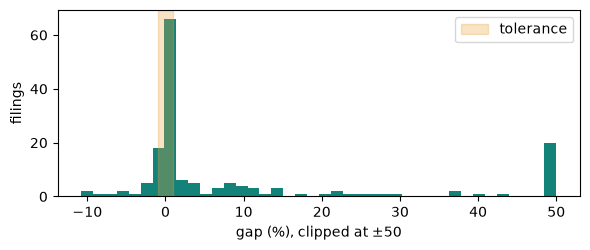

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(rec["gap_pct"].dropna().clip(-0.5, 0.5) * 100, bins=40, color="#13837A")
ax.axvspan(-P["reconcile"]["tolerance"] * 100, P["reconcile"]["tolerance"] * 100, color="#E8A33D", alpha=0.3, label="tolerance")
ax.set_xlabel("gap (%), clipped at ±50"); ax.set_ylabel("filings"); ax.legend()
fig.tight_layout(); fig.savefig(ROOT / P["outputs"]["reports"] / "gap_histogram.png", dpi=150); plt.show()

**Your turn.** On your release, coverage under these two rules will be partial. Raise it honestly: each new rule must be motivated by an artifact and tested, and every filing you still cannot admit gets a root-cause category and an example in `reports/triage.md`. Then run the self-check from your `cs2b/` folder: `PYTHONPATH=src python -m lookthrough.check`.

The triage-category check **fails until you triage**: `report.write_outputs` marks every excluded filing `to_triage`. Replace each with one of the categories in Case Study 2B, Section 7, once you have the evidence.

In [7]:
from lookthrough import check
for name, ok, detail in check.run_checks(ROOT):
    print(f"  {'PASS' if ok else 'FAIL'}  {name}" + (f"  [{detail}]" if not ok and detail else ""))

  PASS  holdings has the required columns
  PASS  coverage.csv has the required columns
  PASS  every filing with SOI rows is in coverage.csv (none dropped)
  PASS  filed totals match NUM
  PASS  holdings sum to the reported holdings_fv
  PASS  gap_pct is computed correctly
  PASS  admission follows the tolerance (1.00%)
  FAIL  every excluded filing has a valid triage_category  [found ['to_triage']; allowed: comparative_leakage, totals_counted, cash_lines, restated_copies, unfunded_commitments, custom_tags, no_identified_holdings, affiliate_split, no_filed_total, other]
  PASS  holdings contain admitted filings only
  PASS  provenance: sampled rows trace to their SOI rows (25 sampled)
